Homework 4, problem 2, part d

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.integrate import quad

In [2]:
# parameters
np.random.seed(42)
mu = 0.2
sigma = 0.5
I0 = 5.0
dt = 0.002
sqrt_dt = np.sqrt(dt)
n_trials = 10000

In [3]:
# boundary conditions
theta_vals = np.array([0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0])
lambda_vals = [0.0, 0.2]

# storeing performance results
sim_results = {lam: {'acc': [], 'rt': []} for lam in lambda_vals}

In [4]:
print("Euler-Maruyama")

for lam in lambda_vals:
    # set weights symmetrically
    ws = (1.0 + lam) / 2.0
    wc = (1.0 + lam) / 2.0
    
    for theta in theta_vals:
        # arrays to monitor crossing flags and trial durations
        choice_correct = np.zeros(n_trials, dtype=bool)
        decision_time = np.zeros(n_trials)
        
        # initialize pools at base current levels
        r1 = np.full(n_trials, I0)
        r2 = np.full(n_trials, I0)
        
        # track active indexes that have not crossed boundaries
        active = np.ones(n_trials, dtype=bool)
        t = 0.0
        max_steps = 60000  # safety threshold window
        
        for step in range(max_steps):
            if not np.any(active):
                break
                
            n_active = np.sum(active)
            
            # generate independent standard white noise elements
            xi1 = np.random.normal(0, 1, n_active)
            xi2 = np.random.normal(0, 1, n_active)
            
            # evaluate differential drift + diffusion components
            dr1 = ((ws - 1.0) * r1[active] - wc * r2[active] + I0 + mu) * dt + sigma * xi1 * sqrt_dt
            dr2 = (-wc * r1[active] + (ws - 1.0) * r2[active] + I0) * dt + sigma * xi2 * sqrt_dt
            
            # state vector array step updates
            r1[active] += dr1
            r2[active] += dr2
            t += dt
            
            # map difference value coordinate changes
            d_active = r1[active] - r2[active]
            
            crossed_upper = (d_active >= theta)
            crossed_lower = (d_active <= -theta)
            has_terminated = crossed_upper | crossed_lower
            
            if np.any(has_terminated):
                # retrieve absolute globally mapped system indices
                global_indices = np.where(active)[0]
                terminated_globals = global_indices[has_terminated]
                
                # assign metrics data points
                choice_correct[terminated_globals] = crossed_upper[has_terminated]
                decision_time[terminated_globals] = t
                
                # switch activity flag off for terminated paths
                active[terminated_globals] = False
                
        if np.any(active):
            d_final = r1[active] - r2[active]
            choice_correct[active] = (d_final > 0)
            decision_time[active] = t
            
        sim_results[lam]['acc'].append(np.mean(choice_correct))
        sim_results[lam]['rt'].append(np.mean(decision_time))

print("simulations complete")

Euler-Maruyama
simulations complete


In [5]:
# perfect drift-diffusion (lambda = 0)
pred_acc_lam0 = 1.0 / (1.0 + np.exp(-mu * theta_vals / (sigma**2)))
pred_rt_lam0 = (theta_vals / mu) * np.tanh((mu * theta_vals) / (2.0 * sigma**2))

# unstable/supercritical network (lambda = 0.2)
pred_acc_lam02 = []
for theta in theta_vals:
    g_func = lambda y: np.exp(-(0.2 * y**2 + 2 * mu * y) / (2 * sigma**2))
    numerator_int, _ = quad(g_func, -theta, 0)
    denominator_int, _ = quad(g_func, -theta, theta)
    pred_acc_lam02.append(numerator_int / denominator_int)
pred_acc_lam02 = np.array(pred_acc_lam02)

# asymptotic performance boundary bound for lambda = 0.2
asymptotic_ceiling = norm.cdf(mu / (sigma * np.sqrt(0.2)))

In [6]:
# printing results
sim_acc_lam02_theta4 = sim_results[0.2]['acc'][-1]
sim_rt_lam02_theta4 = sim_results[0.2]['rt'][-1]

print(f"Unstable Network (lambda = 0.2, theta = 4.0):")
print(f"Simulated Accuracy: {sim_acc_lam02_theta4:.4%}")
print(f"Asymptotic Theory Limit: {asymptotic_ceiling:.4%}")
print(f"Mean Decision Time: {sim_rt_lam02_theta4:.4f} seconds")

# find the specific theta for lambda = 0
theta_matched = -(sigma**2 / mu) * np.log((1.0 - sim_acc_lam02_theta4) / sim_acc_lam02_theta4)
rt_matched = (theta_matched / mu) * np.tanh((mu * theta_matched) / (2.0 * sigma**2))

print(f"Perfect Integrator (lambda = 0) Matching Accuracy ({sim_acc_lam02_theta4:.4%}):")
print(f"Mathematically Required Boundary (theta): {theta_matched:.4f}")
print(f"Predicted Mean Decision Time (⟨T⟩): {rt_matched:.4f} seconds")

Unstable Network (lambda = 0.2, theta = 4.0):
Simulated Accuracy: 81.4600%
Asymptotic Theory Limit: 81.4453%
Mean Decision Time: 8.2636 seconds
Perfect Integrator (lambda = 0) Matching Accuracy (81.4600%):
Mathematically Required Boundary (theta): 1.8502
Predicted Mean Decision Time (⟨T⟩): 5.8208 seconds


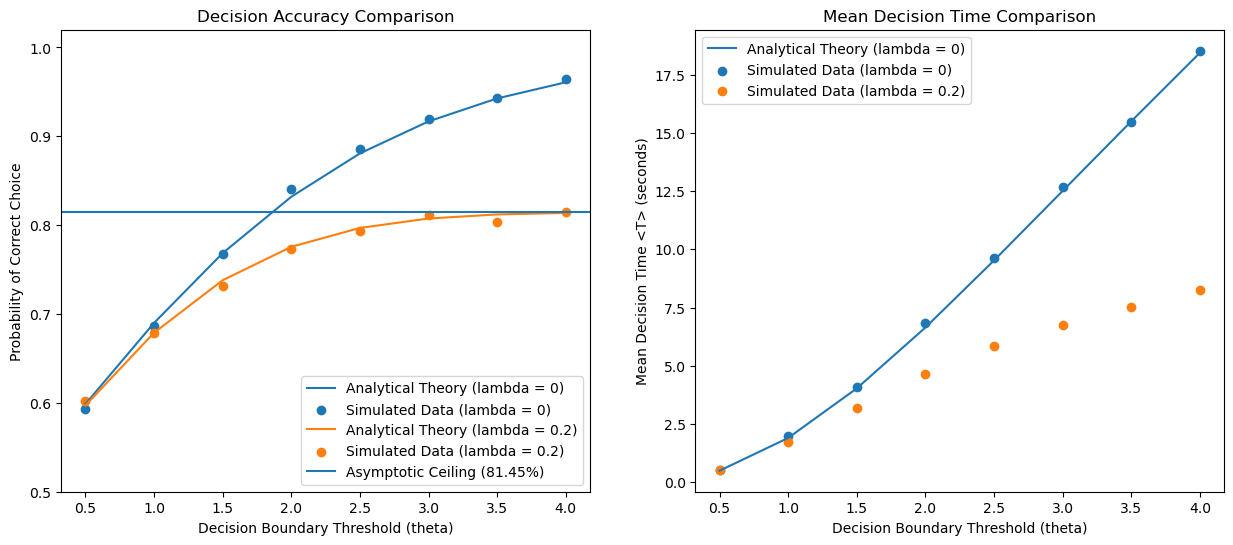

In [7]:
# visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (15, 6))

# accuracy vs boundary threshold
ax1.plot(theta_vals, pred_acc_lam0, label = 'Analytical Theory (lambda = 0)')
ax1.scatter(theta_vals, sim_results[0.0]['acc'], label = 'Simulated Data (lambda = 0)')

ax1.plot(theta_vals, pred_acc_lam02, label='Analytical Theory (lambda = 0.2)')
ax1.scatter(theta_vals, sim_results[0.2]['acc'], label='Simulated Data (lambda = 0.2)')
ax1.axhline(asymptotic_ceiling, label=f'Asymptotic Ceiling ({asymptotic_ceiling:.2%})')

ax1.set_title('Decision Accuracy Comparison')
ax1.set_xlabel(r'Decision Boundary Threshold (theta)')
ax1.set_ylabel('Probability of Correct Choice')
ax1.set_ylim(0.5, 1.02)
ax1.legend(loc = 'lower right')

# mean decision time vs boundary threshold
ax2.plot(theta_vals, pred_rt_lam0, label='Analytical Theory (lambda = 0)')
ax2.scatter(theta_vals, sim_results[0.0]['rt'], label='Simulated Data (lambda = 0)')
ax2.scatter(theta_vals, sim_results[0.2]['rt'], label='Simulated Data (lambda = 0.2)')

ax2.set_title('Mean Decision Time Comparison')
ax2.set_xlabel(r'Decision Boundary Threshold (theta)')
ax2.set_ylabel('Mean Decision Time <T> (seconds)')
ax2.legend(loc = 'upper left')

plt.show()